In [1]:
import cv2
import numpy as np
import onnxruntime as ort

import matplotlib.pyplot as plt

import os
from tqdm import tqdm
import glob
import json
import sys
sys.path.append("../../../drones/code/nn-shard-lite")
from src.utils.metricsevaluator import MetricsEvaluator

In [2]:
# Create an inference session using the ONNX model and specify execution providers
session = ort.InferenceSession("runs/base-pg2/weights/best.onnx")

# Get the model inputs
model_inputs = session.get_inputs()

_, _, h, w = model_inputs[0].shape
model_inputs[0].shape, model_inputs[0].name

([1, 3, 256, 256], 'images')

In [3]:
def preprocess(input_image, input_width, input_height):
    """
    Preprocesses the input image before performing inference.

    Returns:
        image_data: Preprocessed image data ready for inference.
    """
    # Read the input image using OpenCV
    img = cv2.imread(input_image)

    # Get the height and width of the input image
    img_height, img_width = img.shape[:2]

    # Convert the image color space from BGR to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize the image to match the input shape
    img = cv2.resize(img, (input_width, input_height))

    # Normalize the image data by dividing it by 255.0
    image_data = np.array(img) / 255.0

    # Transpose the image to have the channel dimension as the first dimension
    image_data = np.transpose(image_data, (2, 0, 1))  # Channel first

    # Expand the dimensions of the image data to match the expected input shape
    image_data = np.expand_dims(image_data, axis=0).astype(np.float32)

    # Return the preprocessed image data
    return image_data, img_height, img_width

def postprocess(output, input_width, input_height, img_width, img_height, confidence_thres=0.01, iou_thres=0.5):
    """
    Performs post-processing on the model's output to extract bounding boxes, scores, and class IDs.

    Args:
        input_image (numpy.ndarray): The input image.
        output (numpy.ndarray): The output of the model.

    Returns:
        numpy.ndarray: The input image with detections drawn on it.
    """

    # Transpose and squeeze the output to match the expected shape
    outputs = np.transpose(np.squeeze(output[0]))

    # Get the number of rows in the outputs array
    rows = outputs.shape[0]

    # Lists to store the bounding boxes, scores, and class IDs of the detections
    boxes = []
    scores = []
    class_ids = []

    # Calculate the scaling factors for the bounding box coordinates
    x_factor = img_width / input_width
    y_factor = img_height / input_height

    # Iterate over each row in the outputs array
    for i in range(rows):
        # Extract the class scores from the current row
        classes_scores = outputs[i][4:]

        # Find the maximum score among the class scores
        max_score = np.amax(classes_scores)

        # If the maximum score is above the confidence threshold
        if max_score >= confidence_thres:
            # Get the class ID with the highest score
            class_id = np.argmax(classes_scores)

            # Extract the bounding box coordinates from the current row
            x, y, w, h = outputs[i][0], outputs[i][1], outputs[i][2], outputs[i][3]

            # Calculate the scaled coordinates of the bounding box
            left = int((x - w / 2) * x_factor)
            top = int((y - h / 2) * y_factor)
            width = int(w * x_factor)
            height = int(h * y_factor)

            # Add the class ID, score, and box coordinates to the respective lists
            class_ids.append(class_id)
            scores.append(max_score)
            boxes.append([left, top, width, height])

    # Apply non-maximum suppression to filter out overlapping bounding boxes
    indices = cv2.dnn.NMSBoxes(boxes, scores, confidence_thres, iou_thres)

    # Iterate over the selected indices after non-maximum suppression
    final_boxes = []
    final_scores = []
    final_class_ids = []
    for i in indices:
        # Get the box, score, and class ID corresponding to the index
        final_boxes.append(boxes[i])
        final_scores.append(scores[i])
        final_class_ids.append(class_ids[i])

    # Return the modified input image
    return final_boxes, final_scores, final_class_ids

In [4]:
img_name = "datasets/pg/images/bee_working/BeeWorking_H230_Cam3_meeting_5HO_STATIC_20fps_r1_20220201_120841_10fps__20.jpg"

image_data, img_height, img_width = preprocess(img_name, w, h)
ort_inputs = {model_inputs[0].name: image_data}
output = session.run(None, ort_inputs)
boxes, scores, class_ids = postprocess(output, w, h, img_width, img_height, 0.1)

In [5]:
output

[array([[[5.3655820e+00, 1.3948099e+01, 2.1297813e+01, ...,
          1.7600000e+02, 2.0800000e+02, 2.4000000e+02],
         [1.2507109e+01, 9.4291697e+00, 8.0403719e+00, ...,
          2.4000000e+02, 2.4000000e+02, 2.4000000e+02],
         [1.1518128e+01, 2.7926884e+01, 4.2645523e+01, ...,
          4.8000000e+02, 4.8000000e+02, 4.8000000e+02],
         [2.4934910e+01, 1.8724466e+01, 1.6038855e+01, ...,
          4.8000000e+02, 4.8000000e+02, 4.8000000e+02],
         [1.7499924e-04, 5.8770180e-05, 1.2090802e-04, ...,
          1.0669231e-05, 1.0251999e-05, 9.3579292e-06]]], dtype=float32)]

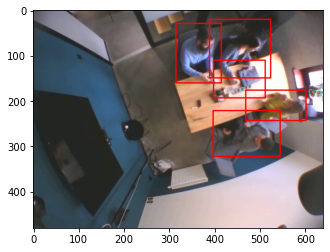

In [6]:
# Read the input image using OpenCV
img = cv2.imread(img_name)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

for box in boxes:
    x1, y1, w, h = box
    cv2.rectangle(img, (int(x1), int(y1)), (int(x1 + w), int(y1 + h)), (255, 0, 0), 2)

plt.imshow(img)

In [7]:
evaluator = MetricsEvaluator(
    is_relative_coordinates=False,
    is_xywh_coordinates=True,
)

with open("../YOLOX/datasets/pg_coco/annotations/instances_test.json", "rt") as f:
    test_data = json.load(f)

name_mapper = {}
id_mapper = {}
for i in test_data["images"]:
    name_mapper[i["file_name"]] = i["id"]
    id_mapper[i["id"]] = i["file_name"]

print(test_data["annotations"][0])

for annotation in test_data["annotations"]:
    evaluator.add_gt_box(
        img_path=annotation["image_id"],
        class_name=annotation["category_id"],
        bbox=annotation["bbox"]
    )

img_pths = sorted(glob.glob("../YOLOX/datasets/pg_coco/test2017/*.jpg"))

{'id': 1700000, 'image_id': 170, 'category_id': 0, 'segmentation': [[398.0, 179.0, 126.0, 58.0]], 'area': 7308.0, 'bbox': [398.0, 179.0, 126.0, 58.0], 'iscrowd': 0}


In [8]:
session = ort.InferenceSession("runs/base-pg2/weights/best.onnx")

# Get the model inputs
model_inputs = session.get_inputs()

_, _, h, w = model_inputs[0].shape

for img_pth in tqdm(img_pths):
    image_data, img_height, img_width = preprocess(img_pth, w, h)
    ort_inputs = {model_inputs[0].name: image_data}
    output = session.run(None, ort_inputs)
    boxes, scores, class_ids = postprocess(output, w, h, img_width, img_height, 0.01)
    
    for b, s, c in zip(boxes, scores, class_ids):
        evaluator.add_det_box(
            img_path=name_mapper[os.path.basename(img_pth)],
            class_name=c,
            bbox=b,
            confidence=s
        )

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4558/4558 [01:49<00:00, 41.74it/s]


In [9]:
output[0]

array([[[4.6117287e+00, 1.5882707e+01, 2.2543179e+01, ...,
         1.7600000e+02, 2.0800000e+02, 2.4000000e+02],
        [1.2643609e+01, 5.0731378e+00, 3.9760392e+00, ...,
         2.4000000e+02, 2.4000000e+02, 2.4000000e+02],
        [9.4317513e+00, 2.9002169e+01, 3.5762535e+01, ...,
         4.8000000e+02, 4.8000000e+02, 4.8000000e+02],
        [2.4959787e+01, 9.9555845e+00, 7.7329803e+00, ...,
         4.8000000e+02, 4.8000000e+02, 4.8000000e+02],
        [1.6096234e-04, 5.8531761e-05, 1.1354685e-05, ...,
         1.0609627e-05, 9.8943710e-06, 8.7022781e-06]]], dtype=float32)

In [10]:
res = evaluator.eval_conf_vals(0.5, 1)[0]

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


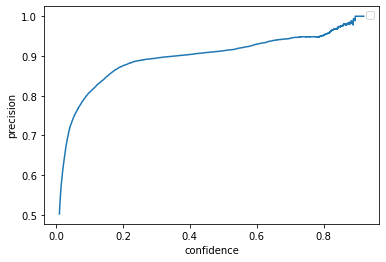

In [19]:
plt.plot(res["confidence"], res["precision"])
plt.xlabel("confidence")
plt.ylabel("precision")
plt.legend()

Text(0, 0.5, 'recall')

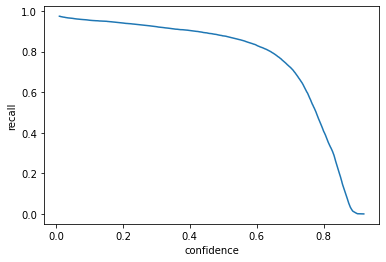

In [20]:
plt.plot(res["confidence"], res["recall"])
plt.xlabel("confidence")
plt.ylabel("recall")

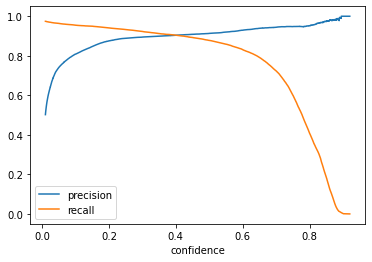

In [21]:
plt.plot(res["confidence"], res["precision"], label="precision")
plt.plot(res["confidence"], res["recall"], label="recall")
# plt.title("exp5")
# plt.vlines(0.11, 0, 1, label="0.11", colors="r")

plt.xlabel("confidence")
plt.legend()

Text(0, 0.5, 'precision')

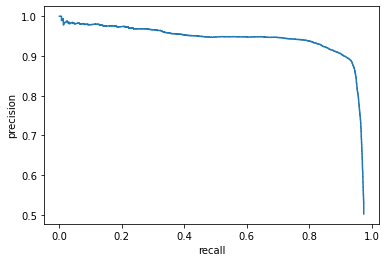

In [22]:
plt.plot(res["recall"], res["precision"])
plt.xlabel("recall")
plt.ylabel("precision")

In [23]:
precision = res["total TP"] / (res["total TP"] + res["total FP"])
recall = res["total TP"] / (res["total positives"])

f_score = 2 * precision * recall / (precision + recall)

precision, recall, f_score

(0.502273066030705, 0.9744090219041422, 0.6628636061865302)

In [24]:
res["AP"]

0.9224758727860581